# GPR & GNSS Survey Line Processing Pipeline: Part 1 - Geometry Cleaning

This tool processes noisy polyline data from field surveys (e.g., raw GNSS paths, GPR tracks) to mathematically recover the true trajectory of the survey. Raw field data often contains stationary clusters (from pausing during the survey) and multipath outliers (spikes from signal bounce in dense canopies). 

**Interactive Processing Pipeline:**
1. **Automated Loading:** Extracts raw geometries directly from `.kmz`, `.kml`, or `.shp` files.
2. **CRS Projection:** Automatically detects geographic coordinates (Lat/Lon) and projects them to a local metric grid (UTM) for accurate distance calculations.
3. **De-Clustering:** Removes consecutive points that fall within a minimum distance threshold, cleaning up stationary scatter.
4. **Outlier Filtering:** Applies a geometric high-pass filter to drop vertices that cause severe, unrealistic angular deviations from the local baseline.
5. **Interactive Simplification & Smoothing:**
   - **Original Vertices (Ramer-Douglas-Peucker):** Best for `straight` or `angular` lines. Strictly retains a subset of original field nodes, preserving sharp azimuth changes.
   - **Smoothed Vertices (B-Spline):** Best for `curving` wanders. Computes a fluid, best-fit path through the center of the noise.

In [ ]:
# ==========================================
# CONFIGURATION PARAMETERS
# ==========================================
from local_paths import RAW_LINE, CLEANED_LINE

# 1. Input / Output
input_filepath = RAW_LINE
output_filepath = CLEANED_LINE

# 2. Shape and Vertex Logic
shape_type = 'curving' 
vertex_mode = 'smoothed' 

# 3. Tuning Parameters (in meters)
cluster_tolerance_m = 0.5  
outlier_tolerance_m = 5.0  
simplification_factor = 2.0 

# 4. Field Data Reconciliation (Optional)
known_ground_distance_m = 170.0

In [17]:
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import LineString, Point
from scipy.interpolate import splprep, splev
import warnings
warnings.filterwarnings('ignore')

def estimate_local_utm(gdf):
    """Projects lat/lon data to a local UTM zone for accurate metric distances."""
    if gdf.crs and gdf.crs.is_geographic:
        return gdf.to_crs(gdf.estimate_utm_crs())
    return gdf

def remove_clusters(line, min_dist):
    """Removes points that are too close to the previous point (standing still)."""
    coords = list(line.coords)
    if len(coords) < 2: return line
    
    cleaned = [coords[0]]
    for pt in coords[1:]:
        dist = np.sqrt((pt[0] - cleaned[-1][0])**2 + (pt[1] - cleaned[-1][1])**2)
        if dist >= min_dist:
            cleaned.append(pt)
    return LineString(cleaned)

def remove_outliers(line, max_deviation):
    """Removes vertices that spike severely away from the local path."""
    coords = list(line.coords)
    if len(coords) < 3: 
        return line
    
    cleaned = [coords[0]]
    for i in range(1, len(coords) - 1):
        baseline = LineString([cleaned[-1], coords[i+1]])
        pt = Point(coords[i])
        if pt.distance(baseline) <= max_deviation:
            cleaned.append(coords[i])
            
    cleaned.append(coords[-1])
    if len(cleaned) >= 2:
        return LineString(cleaned)
    else:
        return line

def smooth_line_spline(line, smooth_factor):
    """Applies B-Spline smoothing to generate a fluid path through the nodes."""
    coords = np.array(line.coords)
    x, y = coords[:, 0], coords[:, 1]
    
    if len(coords) <= 3:
        return line
        
    tck, u = splprep([x, y], s=smooth_factor * len(coords), k=min(3, len(coords)-1))
    u_new = np.linspace(u.min(), u.max(), len(coords))
    x_new, y_new = splev(u_new, tck)
    
    return LineString(zip(x_new, y_new))

def process_survey_line(gdf, shape_type, vertex_mode, cluster_tol, outlier_tol, simp_factor):
    """Main pipeline for cleaning the survey line."""
    gdf_metric = estimate_local_utm(gdf)
    
    processed_geoms = []
    for geom in gdf_metric.geometry:
        if geom.geom_type != 'LineString':
            processed_geoms.append(geom)
            continue
            
        # Step 1: Remove stationary clusters (if slider > 0)
        line = remove_clusters(geom, cluster_tol) if cluster_tol > 0 else geom
            
        # Step 2: Remove multipath spikes (if slider > 0)
        line = remove_outliers(line, outlier_tol) if outlier_tol > 0 else line
        
        # Step 3: Simplification & Smoothing
        if vertex_mode == 'original':
            if shape_type == 'straight':
                line = line.simplify(simp_factor * 3, preserve_topology=False)
            elif shape_type == 'angular':
                line = line.simplify(simp_factor, preserve_topology=True)
            elif shape_type == 'curving':
                line = line.simplify(simp_factor * 0.5, preserve_topology=True)
                
        elif vertex_mode == 'smoothed':
            if shape_type == 'straight':
                line = line.simplify(simp_factor * 2)
                line = smooth_line_spline(line, simp_factor * 10)
            elif shape_type == 'angular':
                line = line.simplify(simp_factor, preserve_topology=True)
            elif shape_type == 'curving':
                line = smooth_line_spline(line, simp_factor)
                
        processed_geoms.append(line)
        
    # FIX: Create a dedicated cleaned metric dataframe
    gdf_clean_metric = gdf_metric.copy()
    gdf_clean_metric.geometry = processed_geoms
    
    if gdf.crs:
        gdf_clean = gdf_clean_metric.to_crs(gdf.crs)
    else:
        gdf_clean = gdf_clean_metric
        
    # Return both the Lat/Lon cleaned data and the Metric cleaned data
    return gdf_clean, gdf_clean_metric

In [ ]:
import fiona
import zipfile
import tempfile
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# Explicitly enable KML drivers in Fiona
fiona.drvsupport.supported_drivers['KML'] = 'rw'
fiona.drvsupport.supported_drivers['LIBKML'] = 'rw'

# ==========================================
# 1. LOAD DATA
# ==========================================
try:
    if input_filepath.lower().endswith('.kmz'):
        # Bulletproof Windows KMZ handling: Extract to a temp folder first
        with zipfile.ZipFile(input_filepath, 'r') as kmz:
            kml_filename = [f for f in kmz.namelist() if f.endswith('.kml')][0]
            with tempfile.TemporaryDirectory() as temp_dir:
                kmz.extract(kml_filename, temp_dir)
                temp_kml_path = os.path.join(temp_dir, kml_filename)
                raw_gdf = gpd.read_file(temp_kml_path, driver='KML', engine='fiona')
    elif input_filepath.lower().endswith('.kml'):
        raw_gdf = gpd.read_file(input_filepath, driver='KML', engine='fiona')
    else:
        raw_gdf = gpd.read_file(input_filepath)
        
    print(f"Loaded {len(raw_gdf)} features from {input_filepath}")
except Exception as e:
    raise RuntimeError(f"Failed to load data. Check filepath and format. Underlying error: {e}")

# ==========================================
# 2. INTERACTIVE TUNER
# ==========================================
global_clean_gdf = None

def interactive_tuner(shape_type, vertex_mode, cluster_tol, outlier_tol, simp_factor):
    global global_clean_gdf
    
    # Process data with current slider values
    clean_gdf, metric_clean_gdf = process_survey_line(
        raw_gdf, shape_type, vertex_mode, 
        cluster_tol, outlier_tol, simp_factor
    )
    
    # Save to global variable for the export cell
    global_clean_gdf = clean_gdf
    
    # Calculate 2D Length
    metric_raw_gdf = estimate_local_utm(raw_gdf)
    raw_2d_length = metric_raw_gdf.length.sum()
    clean_2d_length = metric_clean_gdf.length.sum()
    
    # Visual QC Plot
    fig, ax = plt.subplots(figsize=(10, 8))
    raw_gdf.plot(ax=ax, color='lightgray', linewidth=4, label='Raw Input', zorder=1)
    clean_gdf.plot(ax=ax, color='blue', linewidth=2, label=f'Cleaned ({shape_type}, {vertex_mode})', zorder=2)
    
    plt.title("Interactive Survey Line Tuning")
    plt.xlabel("Longitude / Easting")
    plt.ylabel("Latitude / Northing")
    
    # Force the legend outside the plot box!
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout() 
    plt.show()
    
    # Print dynamic statistics
    print("-" * 40)
    print(f"Raw 2D Map Length:     {raw_2d_length:.2f} m")
    print(f"Cleaned 2D Map Length: {clean_2d_length:.2f} m")
    print(f"Map Distance Saved:    {raw_2d_length - clean_2d_length:.2f} m")

    if known_ground_distance_m:
        scaling_factor = known_ground_distance_m / clean_2d_length
        print(f"\n3D Odometer Ground Distance: {known_ground_distance_m:.2f} m")
        print(f"Scaling Factor (3D/2D):      {scaling_factor:.4f}")
    print("-" * 40)

# Set up the UI controls
ui = widgets.interactive(
    interactive_tuner,
    shape_type=widgets.Dropdown(options=['straight', 'angular', 'curving'], value=shape_type, description='Shape:'),
    vertex_mode=widgets.Dropdown(options=['smoothed', 'original'], value=vertex_mode, description='Vertices:'),
    cluster_tol=widgets.FloatSlider(value=cluster_tolerance_m, min=0.0, max=5.0, step=0.1, description='Cluster (m):'),
    outlier_tol=widgets.FloatSlider(value=outlier_tolerance_m, min=0.0, max=15.0, step=0.5, description='Outlier (m):'),
    simp_factor=widgets.FloatSlider(value=simplification_factor, min=0.1, max=10.0, step=0.1, description='Smooth Factor:')
)

# Display the interactive interface
display(ui)

Loaded 1 features from D:\Documents\Field_Operations\Project_Support\Bateman-Schreiber\GPRlines_measured\line_7.kmz


interactive(children=(Dropdown(description='Shape:', index=1, options=('straight', 'angular', 'curving'), valu…

In [19]:
# ==========================================
# EXPORT CELL
# Run this ONLY when you are happy with the visual results above!
# ==========================================

if global_clean_gdf is not None:
    global_clean_gdf.to_file(output_filepath)
    print(f"Success! Saved your custom-tuned line to:\n{output_filepath}")
else:
    print("Error: No cleaned data found. Please adjust the sliders in the cell above first.")

Success! Saved your custom-tuned line to:
D:\Documents\Field_Operations\Project_Support\Bateman-Schreiber\GPRlines_cleaned\line_7.shp


# GPR & GNSS Survey Line Processing Pipeline: Part 2 - Topo Extraction & Metadata

This operation takes the custom-tuned survey line from Part 1 and a high-resolution Digital Elevation Model (DEM) to generate a topographic profile tailored for GPR processing software.

**Extraction & Export Pipeline:**
1. **Line Discretization:** Interpolates vertices at regular, user-defined intervals along the path (e.g., matching your exact GPR trace spacing).
2. **CRS Synchronization:** Reprojects the trace points to perfectly match the coordinate system of the input DEM matrix.
3. **Bilinear Interpolation:** Samples the DEM using first-order (bilinear) interpolation across the sub-pixel grid, preventing artificial "stair-steps" in the elevation profile.
4. **Data Export:** Generates a clean `.csv` containing Easting, Northing, Elevation, and cumulative 2D profile distance.
5. **Provenance Logging:** Automatically generates a `.txt` metadata file recording the exact DEM used, the line cleaning parameters, and timestamps for reproducible science.

In [ ]:
# ==========================================
# TOPO PROFILE CONFIGURATION
# ==========================================
from local_paths import DEM, TOPO_CSV

# 1. Inputs
topo_input_line = output_filepath  # Uses the cleaned line from Phase 1
dem_filepath = DEM 

# 2. Outputs
output_csv_filepath = TOPO_CSV

# 3. Parameters
trace_spacing_m = 0.50

In [26]:
import rasterio
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

def extract_topo_profile(line_path, dem_path, spacing):
    """Interpolates points along a line and extracts bilinear elevations from a DEM."""
    # 1. Load the cleaned line
    try:
        line_gdf = gpd.read_file(line_path)
    except Exception as e:
        raise RuntimeError(f"Could not load line shapefile. Error: {e}")
        
    # Ensure it's in a metric projection
    line_metric = estimate_local_utm(line_gdf)
    
    geom = line_metric.geometry.iloc[0]
    if geom.geom_type != 'LineString':
        raise ValueError("The input shapefile must contain a LineString geometry.")

    # 2. Interpolate points at the requested interval
    distances = np.arange(0, geom.length, spacing)
    if distances[-1] != geom.length:
        distances = np.append(distances, geom.length)
        
    points_metric = [geom.interpolate(d) for d in distances]
    pts_gdf = gpd.GeoDataFrame({'Distance_m': distances}, geometry=points_metric, crs=line_metric.crs)

    # 3. Load the DEM and sample it using Bilinear Interpolation
    try:
        with rasterio.open(dem_path) as src:
            dem_crs = src.crs
            pts_dem_crs = pts_gdf.to_crs(dem_crs)
            
            # Read the first band of the DEM into a numpy array
            dem_array = src.read(1)
            
            eastings = [pt.x for pt in pts_dem_crs.geometry]
            northings = [pt.y for pt in pts_dem_crs.geometry]
            
            # Calculate fractional row/col indices using the inverse transform
            inv_transform = ~src.transform
            
            # Process point-by-point to avoid Python sequence multiplication errors
            cols_rows = [inv_transform * (x, y) for x, y in zip(eastings, northings)]
            cols = [cr[0] for cr in cols_rows]
            rows = [cr[1] for cr in cols_rows]
            
            # Perform bilinear interpolation (order=1) across the sub-pixel grid
            elevations = map_coordinates(dem_array, [rows, cols], order=1, mode='nearest')
            
    except Exception as e:
        raise RuntimeError(f"Failed to read or sample the DEM. Check filepath and format. Error: {e}")

    # 4. Compile everything into a Pandas DataFrame
    profile_df = pd.DataFrame({
        'Distance_m': distances,
        'Easting': eastings,
        'Northing': northings,
        'Elevation_m': elevations
    })
    
    # Clean up NoData values (often represented as extreme negative numbers)
    profile_df['Elevation_m'] = profile_df['Elevation_m'].apply(lambda x: x if x > -10000 else np.nan)
    
    return profile_df, dem_crs

Sampling DEM every 0.5 meters...
----------------------------------------
Total Trace Points Extracted: 23
Total Profile Length:         10.64 m
Elevation Range:              361.80 m to 362.26 m
Points outside DEM coverage:  0
----------------------------------------


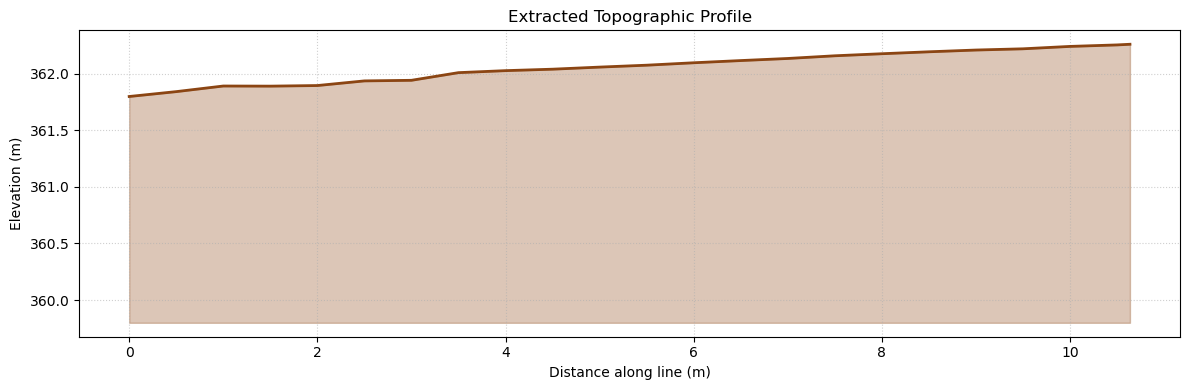


Successfully saved topographic profile to:
D:\Documents\Field_Operations\Project_Support\Bateman-Schreiber\GPRlines_cleaned\line_5_topo.csv
(Coordinate system: EPSG:26917)


In [27]:
# 1. Process the Topo Profile
print(f"Sampling DEM every {trace_spacing_m} meters...")
topo_df, dem_crs = extract_topo_profile(topo_input_line, dem_filepath, trace_spacing_m)

# 2. Display Statistics
missing_data = topo_df['Elevation_m'].isna().sum()
print("-" * 40)
print(f"Total Trace Points Extracted: {len(topo_df)}")
print(f"Total Profile Length:         {topo_df['Distance_m'].max():.2f} m")
print(f"Elevation Range:              {topo_df['Elevation_m'].min():.2f} m to {topo_df['Elevation_m'].max():.2f} m")
print(f"Points outside DEM coverage:  {missing_data}")
print("-" * 40)

# 3. Visual QC Plot (Distance vs. Elevation)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(topo_df['Distance_m'], topo_df['Elevation_m'], color='saddlebrown', linewidth=2)
ax.fill_between(topo_df['Distance_m'], topo_df['Elevation_m'], topo_df['Elevation_m'].min() - 2, color='saddlebrown', alpha=0.3)

plt.title("Extracted Topographic Profile")
plt.xlabel("Distance along line (m)")
plt.ylabel("Elevation (m)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# 4. Export to CSV
topo_df.to_csv(output_csv_filepath, index=False)
print(f"\nSuccessfully saved topographic profile to:\n{output_csv_filepath}")
print(f"(Coordinate system: {dem_crs})")

In [28]:
# ==========================================
# METADATA EXPORT CELL
# ==========================================
import datetime
import os

# Automatically generate a metadata filename based on the CSV output name
metadata_filepath = output_csv_filepath.replace('.csv', '_processing_metadata.txt')

# Compile the text block using our global configuration variables
metadata_content = f"""=========================================
GPR SURVEY LINE PROCESSING METADATA
Generated: {datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")}
=========================================

1. INPUT DATA
-------------
Raw Line Geometry: {input_filepath}
DEM Source File:   {dem_filepath}

2. GEOMETRY CLEANING PARAMETERS
-------------------------------
Shape Type Logic:        {shape_type}
Vertex Handling:         {vertex_mode}
Cluster Tolerance (m):   {cluster_tolerance_m}
Outlier Tolerance (m):   {outlier_tolerance_m}
Simplification Factor:   {simplification_factor}

3. TOPOGRAPHIC EXTRACTION PARAMETERS
------------------------------------
Trace Spacing (m):       {trace_spacing_m}

4. OUTPUT FILES
---------------
Cleaned Shapefile: {output_filepath}
Topo Profile CSV:  {output_csv_filepath}
=========================================
"""

# Write the text to the file
with open(metadata_filepath, 'w') as f:
    f.write(metadata_content)

print(f"Metadata log successfully written to:\n{metadata_filepath}")

Metadata log successfully written to:
D:\Documents\Field_Operations\Project_Support\Bateman-Schreiber\GPRlines_cleaned\line_5_topo_processing_metadata.txt
